In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [2]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomCNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

In [3]:
def imshow(img):
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)
    img = img * std + mean
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для обучения: {device}")

Устройство для обучения: cuda


In [5]:
transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
    ])

In [6]:
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

In [7]:
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

Files already downloaded and verified
Files already downloaded and verified


In [8]:
classes = train_dataset.classes

In [9]:
print(f"Классы из датасета: {classes}")

Классы из датасета: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [10]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=0)

In [11]:
sample_img, sample_label = train_dataset[0]
print(f"Обучающая выборка: {len(train_dataset)} шт. | Тестовая: {len(test_dataset)} шт.")
print(f"Форма изображения: {sample_img.shape} | Метка: {sample_label} ({classes[sample_label]})")

Обучающая выборка: 50000 шт. | Тестовая: 10000 шт.
Форма изображения: torch.Size([3, 32, 32]) | Метка: 6 (frog)


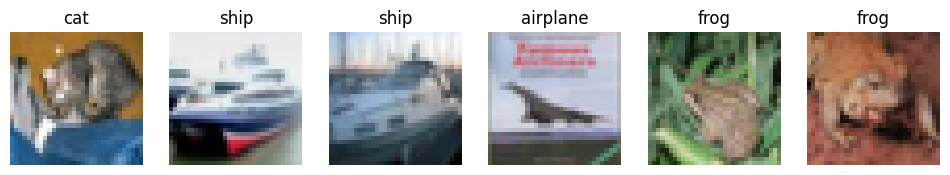

In [12]:
images, labels = next(iter(test_loader))
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    plt.sca(axes[i])
    imshow(images[i])
    axes[i].set_title(classes[labels[i]])
    axes[i].axis('off')
plt.show()

In [13]:
model = CustomCNN(num_classes=10).to(device)
EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [14]:
train_losses = []
print("\nНачало обучения...")
for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler.step()
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    train_losses.append(epoch_loss)
    print(f"Эпоха {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Время: {time.time() - start_time:.1f} сек.")


Начало обучения...
Эпоха 01/20 | Loss: 1.6304 | Train Acc: 39.89% | Время: 32.4 сек.
Эпоха 02/20 | Loss: 1.1475 | Train Acc: 58.24% | Время: 31.4 сек.
Эпоха 03/20 | Loss: 0.9522 | Train Acc: 66.19% | Время: 31.4 сек.
Эпоха 04/20 | Loss: 0.8254 | Train Acc: 71.09% | Время: 31.4 сек.
Эпоха 05/20 | Loss: 0.7283 | Train Acc: 75.03% | Время: 31.4 сек.
Эпоха 06/20 | Loss: 0.6429 | Train Acc: 78.00% | Время: 31.4 сек.
Эпоха 07/20 | Loss: 0.5873 | Train Acc: 79.96% | Время: 31.5 сек.
Эпоха 08/20 | Loss: 0.5347 | Train Acc: 81.89% | Время: 31.6 сек.
Эпоха 09/20 | Loss: 0.4833 | Train Acc: 83.79% | Время: 31.5 сек.
Эпоха 10/20 | Loss: 0.4503 | Train Acc: 84.94% | Время: 31.5 сек.
Эпоха 11/20 | Loss: 0.4082 | Train Acc: 86.28% | Время: 31.3 сек.
Эпоха 12/20 | Loss: 0.3770 | Train Acc: 87.25% | Время: 31.4 сек.
Эпоха 13/20 | Loss: 0.3382 | Train Acc: 88.82% | Время: 31.3 сек.
Эпоха 14/20 | Loss: 0.3129 | Train Acc: 89.46% | Время: 31.3 сек.
Эпоха 15/20 | Loss: 0.2842 | Train Acc: 90.34% | Время: 

In [15]:
model.eval()
test_loss, correct, total = 0.0, 0, 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

In [16]:
print("=" * 55)
print(f"Test Loss: {test_loss / total:.4f} | Test Accuracy: {100.0 * correct / total:.2f}%")
print("=" * 55)

Test Loss: 0.3198 | Test Accuracy: 89.67%


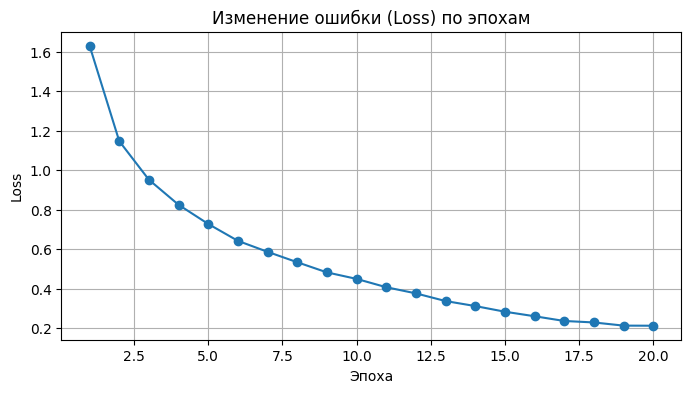

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o')
plt.title('Изменение ошибки (Loss) по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)
plt.show()